# Wine Quality Prediction — Is this a *good* wine?

**Problem.** A winery (or a retailer buying from many producers) wants a quick, cheap signal of whether a batch of wine is likely to be rated as *good* by expert tasters, using only standard lab measurements (acidity, sugar, sulphates, alcohol, ...). Expert tasting panels are slow and expensive; lab analysis is routine.

**Approach.** We use the [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) (Cortez et al., 2009): 6,497 Portuguese *Vinho Verde* wines (1,599 red, 4,898 white), each with 11 physicochemical measurements and a median expert quality score from 0 to 10.

We turn it into a **binary classification** problem:

* `good = 1` if `quality >= 7`, otherwise `0`

The model outputs the **probability that a wine is good**. That probability can be used to:

* prioritise which batches go to the (expensive) tasting panel,
* flag promising batches for a premium label,
* give winemakers fast feedback while blending.

**Metric.** Classes are imbalanced (~20% good), so we use **ROC AUC** as the main metric and also look at precision / recall.

**Plan**
1. Data preparation & cleaning
2. EDA and feature importance (correlation, mutual information, distributions)
3. Train and tune several models: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting
4. Pick the best model and evaluate it on the held-out test set

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, classification_report, roc_curve, precision_recall_curve
from sklearn.model_selection import KFold

pd.set_option('display.max_columns', 20)
sns.set_theme(style='whitegrid')
SEED = 1

## 1. Data preparation and cleaning

In [2]:
df_red = pd.read_csv('data/winequality-red.csv', sep=';')
df_white = pd.read_csv('data/winequality-white.csv', sep=';')

df_red['wine_type'] = 'red'
df_white['wine_type'] = 'white'

df = pd.concat([df_red, df_white], ignore_index=True)
print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Column names contain spaces — normalise them to `snake_case`, as we did in the course.

In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
dtype: object

In [4]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64


No missing values. However, the dataset contains **duplicate rows** — the same measurements and score appearing more than once (likely the same wine measured or recorded twice). If we keep them, the same wine can end up in both train and test, which inflates validation scores. We drop them.

In [5]:
n_dup = df.duplicated().sum()
print(f'Duplicated rows: {n_dup} ({n_dup / len(df):.1%})')

df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Duplicated rows: 1177 (18.1%)
Shape after dropping duplicates: (5320, 13)


In [6]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,5320.0,7.215,1.320,3.800,6.400,7.000,7.700,15.900
volatile_acidity,5320.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric_acid,5320.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual_sugar,5320.0,5.048,4.500,0.600,1.800,2.700,7.500,65.800
chlorides,5320.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free_sulfur_dioxide,5320.0,30.037,17.805,1.000,16.000,28.000,41.000,289.000
total_sulfur_dioxide,5320.0,114.109,56.774,6.000,74.000,116.000,153.250,440.000
density,5320.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
ph,5320.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5320.0,0.533,0.150,0.220,0.430,0.510,0.600,2.000


Some features (e.g. `residual_sugar`, `chlorides`, `free_sulfur_dioxide`, `total_sulfur_dioxide`) have long right tails — max values far above the 75th percentile. Tree models don't care, but for Logistic Regression we'll standardise the features.

### Target variable

good
0    0.81
1    0.19
Name: proportion, dtype: float64


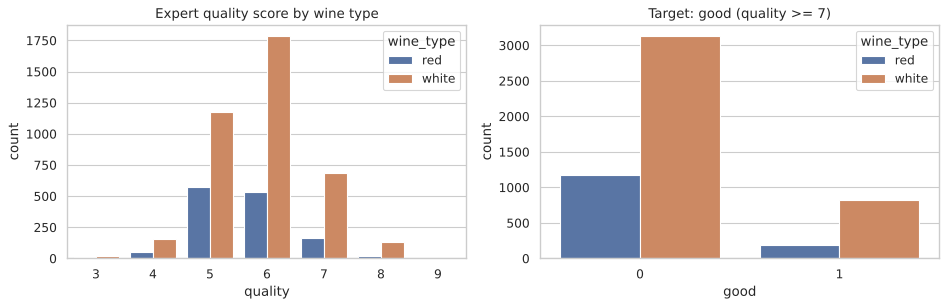

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='quality', hue='wine_type', ax=axes[0])
axes[0].set_title('Expert quality score by wine type')

df['good'] = (df.quality >= 7).astype(int)
sns.countplot(data=df, x='good', hue='wine_type', ax=axes[1])
axes[1].set_title('Target: good (quality >= 7)')
plt.tight_layout()
plt.show()

print(df.good.value_counts(normalize=True).round(3))

The raw score is concentrated in 5–6; very few wines get 3, 4, 8 or 9. A score of 7 or more is a natural "good wine" threshold and gives roughly a 19% positive class. Predicting the exact score from 11 lab measurements is hard; separating good from average wine is what the business actually needs.

### Train / validation / test split (60 / 20 / 20)

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df.good)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=SEED, stratify=df_full_train.good)

for name, d in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{name:5s} {len(d):5d} rows, good rate = {d.good.mean():.3f}')

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train.good.values
y_val = df_val.good.values
y_test = df_test.good.values
y_full_train = df_full_train.good.values

train  3192 rows, good rate = 0.190
val    1064 rows, good rate = 0.190
test   1064 rows, good rate = 0.190


## 2. Exploratory data analysis

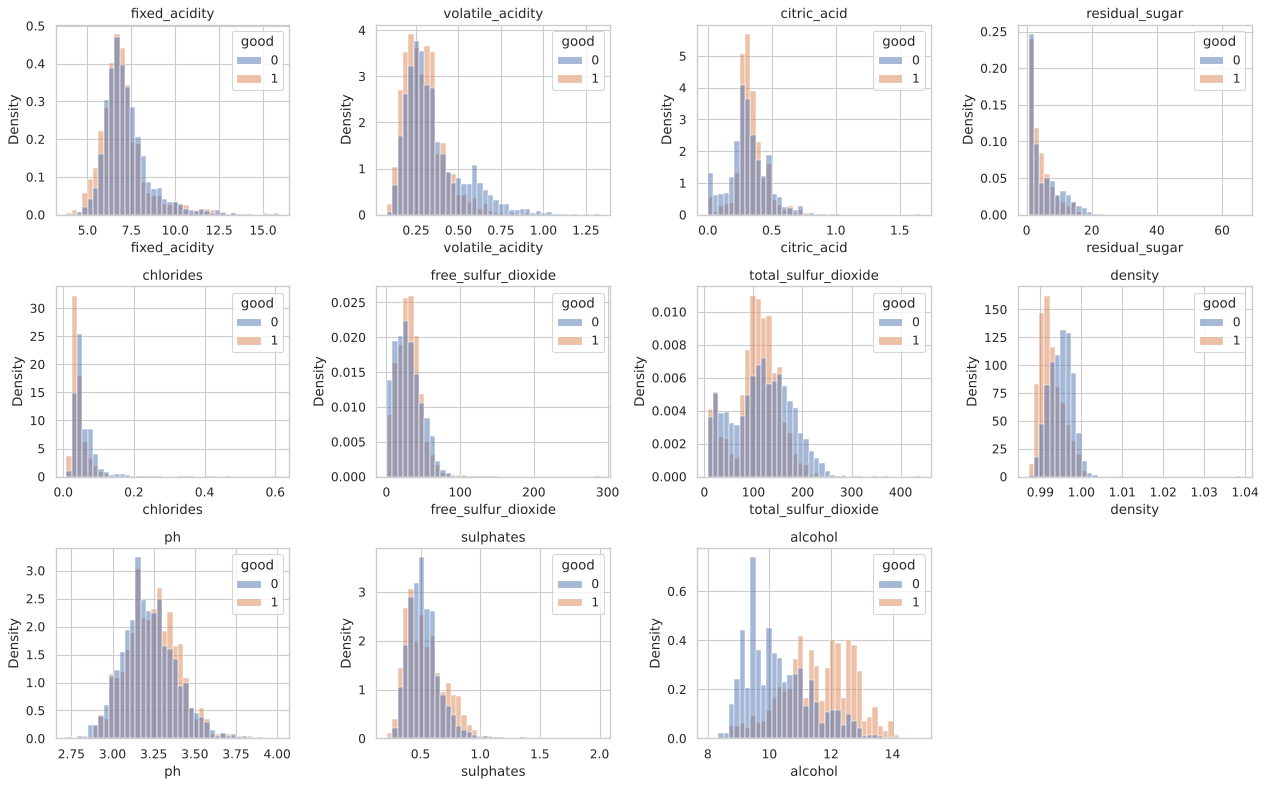

In [9]:
numerical = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
             'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
             'ph', 'sulphates', 'alcohol']
categorical = ['wine_type']

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, numerical):
    sns.histplot(data=df_full_train, x=col, hue='good', stat='density', common_norm=False, bins=40, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

Visually, **alcohol** separates the classes most clearly: good wines have noticeably higher alcohol. Good wines also tend to have lower **density** and **volatile acidity** (the "vinegar" note) and slightly lower **chlorides**.

### Correlation

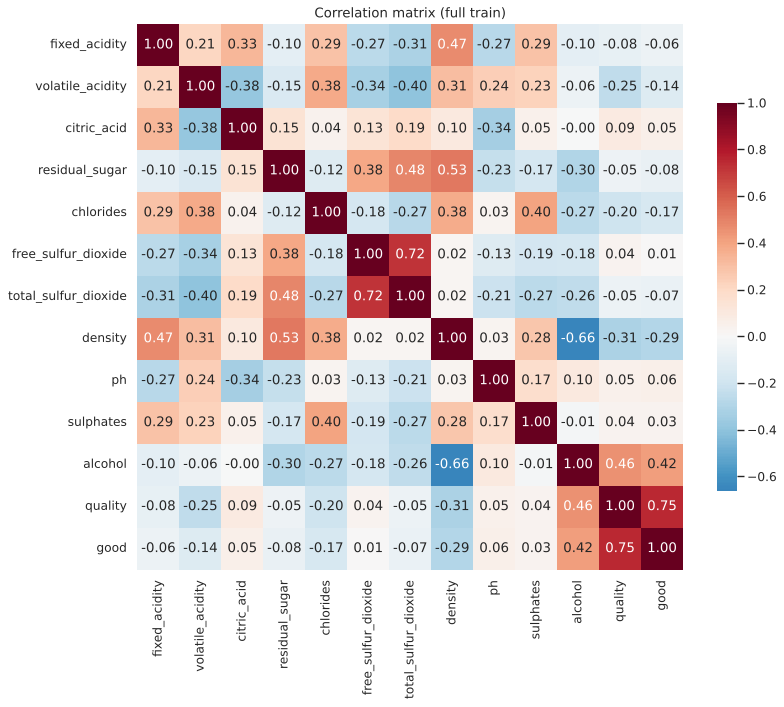

In [10]:
corr = df_full_train[numerical + ['quality', 'good']].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('Correlation matrix (full train)')
plt.show()

In [11]:
corr_target = df_full_train[numerical].corrwith(df_full_train.good).sort_values(key=abs, ascending=False)
corr_target.to_frame('correlation_with_good').round(3)

,correlation_with_good
alcohol,0.421
density,-0.292
chlorides,-0.168
volatile_acidity,-0.142
residual_sugar,-0.076
total_sulfur_dioxide,-0.067
fixed_acidity,-0.056
ph,0.055
citric_acid,0.055
sulphates,0.034


* `alcohol` is by far the strongest single predictor (r ≈ 0.42).
* `density` is negatively correlated with `good`, but it is also strongly correlated with `alcohol` (≈ −0.67) and `residual_sugar` (≈ +0.52) — it is largely a function of those two, so it carries overlapping information.
* `free_sulfur_dioxide` and `total_sulfur_dioxide` are correlated with each other, as expected.

### Risk ratio for wine type (categorical feature)

In [12]:
global_rate = df_full_train.good.mean()
by_type = df_full_train.groupby('wine_type').good.agg(['mean', 'count'])
by_type['diff'] = by_type['mean'] - global_rate
by_type['risk'] = by_type['mean'] / global_rate
print(f'Global good rate: {global_rate:.3f}')
by_type.round(3)

Global good rate: 0.190


,mean,count,diff,risk
wine_type,,,,
red,0.134,1066,-0.055,0.707
white,0.208,3190,0.019,1.098


In [13]:
mi = mutual_info_score(df_full_train.good, df_full_train.wine_type)
print(f'Mutual information (wine_type, good): {mi:.4f}')

Mutual information (wine_type, good): 0.0035


White wines are somewhat more likely to be rated good than reds, but the mutual information is small — `wine_type` alone says little. We keep it as a feature because the chemistry of reds and whites differs (e.g. sulfur dioxide and sugar levels), so the model may use it in interactions.

### Mutual information of binned numerical features
To compare numeric features on the same scale as the categorical one, we bin each into quintiles and compute mutual information with the target.

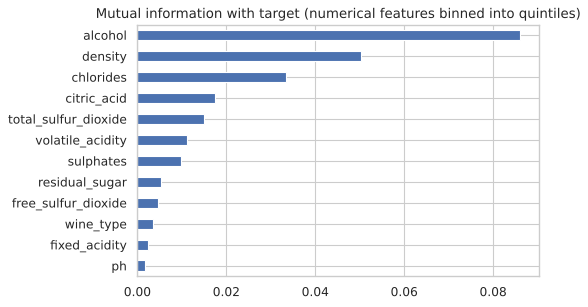

,mutual_info
alcohol,0.0860
density,0.0502
chlorides,0.0334
citric_acid,0.0174
total_sulfur_dioxide,0.0149
volatile_acidity,0.0111
sulphates,0.0097
residual_sugar,0.0052
free_sulfur_dioxide,0.0047
wine_type,0.0035


In [14]:
mi_scores = {}
for col in numerical:
    binned = pd.qcut(df_full_train[col], q=5, duplicates='drop')
    mi_scores[col] = mutual_info_score(binned, df_full_train.good)
mi_scores['wine_type'] = mi

mi_series = pd.Series(mi_scores).sort_values(ascending=False)
mi_series.plot.barh(figsize=(7, 4), color='#4C72B0').invert_yaxis()
plt.title('Mutual information with target (numerical features binned into quintiles)')
plt.tight_layout()
plt.show()
mi_series.round(4).to_frame('mutual_info')

Mutual information agrees with the correlation analysis: **alcohol** and **density** carry the most information, followed by **chlorides**. `ph`, `fixed_acidity`, `free_sulfur_dioxide` and `wine_type` carry very little on their own.

## 3. Feature matrix

We use `DictVectorizer` (one-hot encodes `wine_type`, passes numbers through) — the same tool from the course. The same vectorizer is saved with the model so the web service can take JSON dicts directly.

In [15]:
features = numerical + categorical

def prepare_dicts(d):
    return d[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(prepare_dicts(df_train))
X_val = dv.transform(prepare_dicts(df_val))

print(X_train.shape)
list(dv.get_feature_names_out())

(3192, 13)


['alcohol', 'chlorides', 'citric_acid', 'density', 'fixed_acidity', 'free_sulfur_dioxide', 'ph', 'residual_sugar', 'sulphates', 'total_sulfur_dioxide', 'volatile_acidity', 'wine_type=red', 'wine_type=white']

## 4. Model training and tuning

### 4.1 Logistic Regression
Features are on very different scales, so we standardise before fitting. We tune the regularisation strength `C`.

In [16]:
results = {}

for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    lr.fit(X_train, y_train)
    auc = roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1])
    print(f'C={C:<7} val AUC = {auc:.4f}')

C=0.001   val AUC = 0.7790
C=0.01    val AUC = 0.8055
C=0.1     val AUC = 0.8143
C=1       val AUC = 0.8158
C=10      val AUC = 0.8160
C=100     val AUC = 0.8160


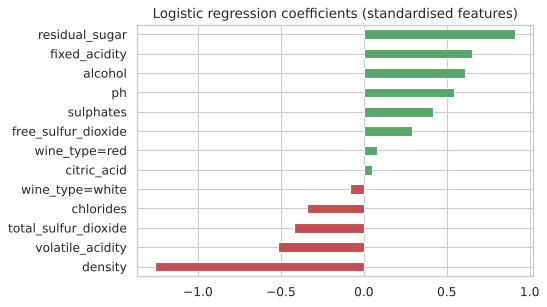

In [17]:
lr = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000))
lr.fit(X_train, y_train)
results['logistic_regression'] = roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1])

coefs = pd.Series(lr[-1].coef_[0], index=dv.get_feature_names_out()).sort_values()
coefs.plot.barh(figsize=(7, 4), color=np.where(coefs > 0, '#55A868', '#C44E52'))
plt.title('Logistic regression coefficients (standardised features)')
plt.tight_layout()
plt.show()

Logistic regression reaches about 0.82 validation AUC (it plateaus for C ≥ 1). Its coefficients largely match the EDA: alcohol and sulphates push towards *good*; density, volatile acidity and chlorides push towards *not good*. The large opposite-signed coefficients for density and residual sugar / fixed acidity come from their strong correlation with each other (density is mostly determined by sugar and alcohol), so individual coefficients should not be over-interpreted.

### 4.2 Decision Tree
Tune `max_depth` first, then `min_samples_leaf`.

In [18]:
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    dt.fit(X_train, y_train)
    auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
    print(f'max_depth={str(depth):>4}  val AUC = {auc:.4f}')

max_depth=   1  val AUC = 0.7114
max_depth=   2  val AUC = 0.7593
max_depth=   3  val AUC = 0.7849
max_depth=   4  val AUC = 0.7872
max_depth=   5  val AUC = 0.7843
max_depth=   6  val AUC = 0.7719
max_depth=   8  val AUC = 0.7403
max_depth=  10  val AUC = 0.6719
max_depth=  15  val AUC = 0.6381
max_depth=None  val AUC = 0.6392


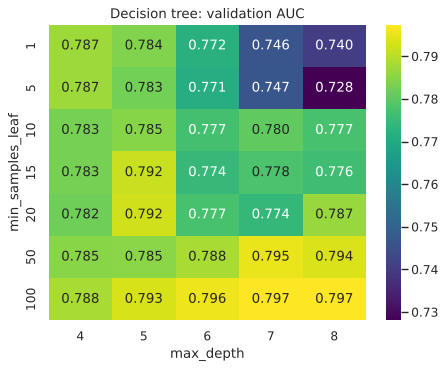

max_depth             7.000000
min_samples_leaf    100.000000
auc                   0.797392
Name: 27, dtype: float64

In [19]:
scores = []
for depth in [4, 5, 6, 7, 8]:
    for leaf in [1, 5, 10, 15, 20, 50, 100]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
        dt.fit(X_train, y_train)
        scores.append((depth, leaf, roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])))

df_dt = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
pivot = df_dt.pivot(index='min_samples_leaf', columns='max_depth', values='auc')
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
plt.title('Decision tree: validation AUC')
plt.show()

best_dt = df_dt.sort_values('auc', ascending=False).iloc[0]
best_dt

In [20]:
dt = DecisionTreeClassifier(max_depth=int(best_dt.max_depth), min_samples_leaf=int(best_dt.min_samples_leaf), random_state=SEED)
dt.fit(X_train, y_train)
results['decision_tree'] = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
print(f"Decision tree val AUC: {results['decision_tree']:.4f}")

# Top of the tree — which splits does it use first?
print(export_text(DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train, y_train),
                  feature_names=list(dv.get_feature_names_out())))

Decision tree val AUC: 0.7974
|--- alcohol <= 10.99
|   |--- volatile_acidity <= 0.21
|   |   |--- class: 0
|   |--- volatile_acidity >  0.21
|   |   |--- class: 0
|--- alcohol >  10.99
|   |--- alcohol <= 11.88
|   |   |--- class: 0
|   |--- alcohol >  11.88
|   |   |--- class: 1



A single tree tops out around 0.79–0.80 AUC. The first split is on alcohol (around 11%), and the second level splits on alcohol again (around 11.9%), which confirms the EDA.

### 4.3 Random Forest
Tune `n_estimators`, then `max_depth`, then `min_samples_leaf`.

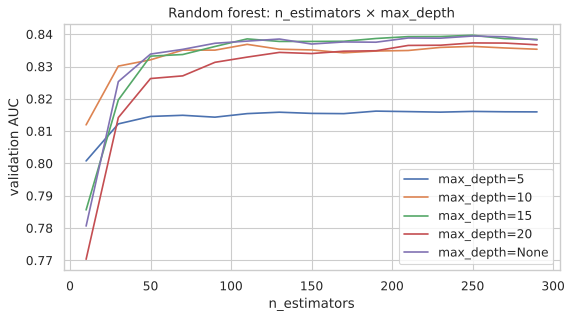

In [21]:
scores = []
for d in [5, 10, 15, 20, None]:
    for n in range(10, 301, 20):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=SEED, n_jobs=-1)
        rf.fit(X_train, y_train)
        scores.append((str(d), n, roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])))

df_rf = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'auc'])

plt.figure(figsize=(8, 4))
for d, g in df_rf.groupby('max_depth', sort=False):
    plt.plot(g.n_estimators, g.auc, label=f'max_depth={d}')
plt.xlabel('n_estimators'); plt.ylabel('validation AUC'); plt.legend()
plt.title('Random forest: n_estimators × max_depth')
plt.show()

In [22]:
scores = []
for leaf in [1, 2, 3, 5, 10, 20]:
    for mf in ['sqrt', 0.5, 1.0]:
        rf = RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_leaf=leaf,
                                    max_features=mf, random_state=SEED, n_jobs=-1)
        rf.fit(X_train, y_train)
        scores.append((leaf, str(mf), roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])))

df_rf2 = pd.DataFrame(scores, columns=['min_samples_leaf', 'max_features', 'auc'])
df_rf2.pivot(index='min_samples_leaf', columns='max_features', values='auc').round(4)

max_features,0.5,1.0,sqrt
min_samples_leaf,,,
1,0.8313,0.8292,0.8379
2,0.8315,0.8282,0.8348
3,0.8311,0.8261,0.8360
5,0.8273,0.8251,0.8340
10,0.8322,0.8259,0.8316
20,0.8302,0.8240,0.8307


In [23]:
best_rf = df_rf2.sort_values('auc', ascending=False).iloc[0]
rf_max_features = best_rf.max_features if best_rf.max_features == 'sqrt' else float(best_rf.max_features)
rf_params = dict(n_estimators=200, max_depth=None, min_samples_leaf=int(best_rf.min_samples_leaf),
                 max_features=rf_max_features, random_state=SEED, n_jobs=-1)
print(rf_params)

rf = RandomForestClassifier(**rf_params).fit(X_train, y_train)
results['random_forest'] = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
print(f"Random forest val AUC: {results['random_forest']:.4f}")

{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'random_state': 1, 'n_jobs': -1}
Random forest val AUC: 0.8379


### 4.4 Gradient Boosting
XGBoost isn't required — scikit-learn's `HistGradientBoostingClassifier` is a fast histogram-based gradient boosting implementation (same idea as LightGBM / XGBoost `hist`). We tune `learning_rate` (≈ `eta`), `max_depth`, `min_samples_leaf` (≈ `min_child_weight`) and the number of iterations, using early stopping on an internal validation split.

In [24]:
scores = []
for lr_ in [0.01, 0.05, 0.1, 0.3]:
    for depth in [3, 4, 6, None]:
        gb = HistGradientBoostingClassifier(learning_rate=lr_, max_depth=depth, max_iter=1000,
                                            early_stopping=True, validation_fraction=0.15,
                                            n_iter_no_change=30, random_state=SEED)
        gb.fit(X_train, y_train)
        scores.append((lr_, str(depth), gb.n_iter_, roc_auc_score(y_val, gb.predict_proba(X_val)[:, 1])))

df_gb = pd.DataFrame(scores, columns=['learning_rate', 'max_depth', 'n_iter', 'auc'])
df_gb.pivot(index='learning_rate', columns='max_depth', values='auc').round(4)

max_depth,3,4,6,None
learning_rate,,,,
0.01,0.8259,0.8276,0.8241,0.8203
0.05,0.8270,0.8258,0.8232,0.8193
0.10,0.8256,0.8280,0.8221,0.8221
0.30,0.8204,0.8202,0.8060,0.8168


In [25]:
best_gb = df_gb.sort_values('auc', ascending=False).iloc[0]
print(best_gb)

scores = []
for leaf in [5, 10, 20, 40, 80]:
    for l2 in [0.0, 1.0, 10.0]:
        gb = HistGradientBoostingClassifier(learning_rate=best_gb.learning_rate,
                                            max_depth=None if best_gb.max_depth == 'None' else int(best_gb.max_depth),
                                            min_samples_leaf=leaf, l2_regularization=l2, max_iter=1000,
                                            early_stopping=True, validation_fraction=0.15,
                                            n_iter_no_change=30, random_state=SEED)
        gb.fit(X_train, y_train)
        scores.append((leaf, l2, gb.n_iter_, roc_auc_score(y_val, gb.predict_proba(X_val)[:, 1])))

df_gb2 = pd.DataFrame(scores, columns=['min_samples_leaf', 'l2_regularization', 'n_iter', 'auc'])
df_gb2.sort_values('auc', ascending=False).head(8).round(4)

learning_rate         0.1
max_depth               4
n_iter                 98
auc              0.828031
Name: 9, dtype: object


,min_samples_leaf,l2_regularization,n_iter,auc
3,10,0.0,66,0.8294
13,80,1.0,94,0.8286
4,10,1.0,109,0.8284
12,80,0.0,125,0.8283
6,20,0.0,98,0.8280
7,20,1.0,157,0.8268
2,5,10.0,90,0.8267
14,80,10.0,176,0.8264


In [26]:
b = df_gb2.sort_values('auc', ascending=False).iloc[0]
gb_params = dict(learning_rate=float(best_gb.learning_rate),
                 max_depth=None if best_gb.max_depth == 'None' else int(best_gb.max_depth),
                 min_samples_leaf=int(b.min_samples_leaf), l2_regularization=float(b.l2_regularization),
                 max_iter=int(b.n_iter), early_stopping=False, random_state=SEED)
print(gb_params)

gb = HistGradientBoostingClassifier(**gb_params).fit(X_train, y_train)
results['gradient_boosting'] = roc_auc_score(y_val, gb.predict_proba(X_val)[:, 1])
print(f"Gradient boosting val AUC: {results['gradient_boosting']:.4f}")

{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 10, 'l2_regularization': 0.0, 'max_iter': 66, 'early_stopping': False, 'random_state': 1}
Gradient boosting val AUC: 0.8311


## 5. Model selection

In [27]:
res = pd.Series(results).sort_values(ascending=False).to_frame('val_auc')
res.round(4)

,val_auc
random_forest,0.8379
gradient_boosting,0.8311
logistic_regression,0.8158
decision_tree,0.7974


A single train/validation split can be noisy, so we confirm the ranking with **5-fold cross-validation** on the full training set (train + validation).

In [28]:
def cv_auc(make_model, df_data, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    aucs = []
    for tr_idx, va_idx in kf.split(df_data):
        d_tr, d_va = df_data.iloc[tr_idx], df_data.iloc[va_idx]
        dv_ = DictVectorizer(sparse=False)
        X_tr = dv_.fit_transform(prepare_dicts(d_tr))
        X_va = dv_.transform(prepare_dicts(d_va))
        m = make_model().fit(X_tr, d_tr.good.values)
        aucs.append(roc_auc_score(d_va.good.values, m.predict_proba(X_va)[:, 1]))
    return np.mean(aucs), np.std(aucs)

candidates = {
    'logistic_regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    'decision_tree': lambda: DecisionTreeClassifier(max_depth=int(best_dt.max_depth),
                                                    min_samples_leaf=int(best_dt.min_samples_leaf), random_state=SEED),
    'random_forest': lambda: RandomForestClassifier(**rf_params),
    'gradient_boosting': lambda: HistGradientBoostingClassifier(**gb_params),
}

cv_rows = []
for name, make_model in candidates.items():
    mean, std = cv_auc(make_model, df_full_train)
    cv_rows.append((name, mean, std))
    print(f'{name:20s} CV AUC = {mean:.4f} ± {std:.4f}')

df_cv = pd.DataFrame(cv_rows, columns=['model', 'cv_auc_mean', 'cv_auc_std']).sort_values('cv_auc_mean', ascending=False)

logistic_regression  CV AUC = 0.8286 ± 0.0152
decision_tree        CV AUC = 0.8080 ± 0.0212
random_forest        CV AUC = 0.8479 ± 0.0132
gradient_boosting    CV AUC = 0.8422 ± 0.0128


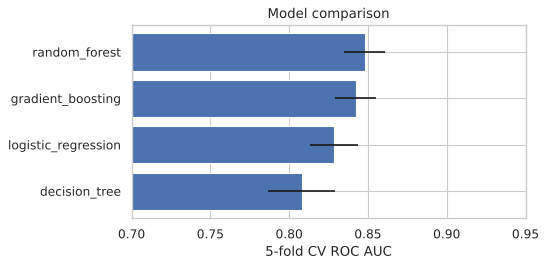

In [29]:
plt.figure(figsize=(7, 3.5))
plt.barh(df_cv.model, df_cv.cv_auc_mean, xerr=df_cv.cv_auc_std, color='#4C72B0')
plt.xlim(0.7, 0.95)
plt.gca().invert_yaxis()
plt.xlabel('5-fold CV ROC AUC')
plt.title('Model comparison')
plt.tight_layout()
plt.show()

**Random Forest** gives the best cross-validated AUC (≈ 0.848), slightly ahead of gradient boosting (≈ 0.842), with the linear model and the single tree well behind. Its tuned parameters (`n_estimators=200`, fully grown trees, small `min_samples_leaf`) are used in `train.py`.

## 6. Final model: train on full train, evaluate on test

In [30]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(prepare_dicts(df_full_train))
X_test = dv.transform(prepare_dicts(df_test))

final_model = RandomForestClassifier(**rf_params).fit(X_full_train, y_full_train)
y_pred = final_model.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, y_pred)
print(f'Test ROC AUC: {test_auc:.4f}')

Test ROC AUC: 0.8460


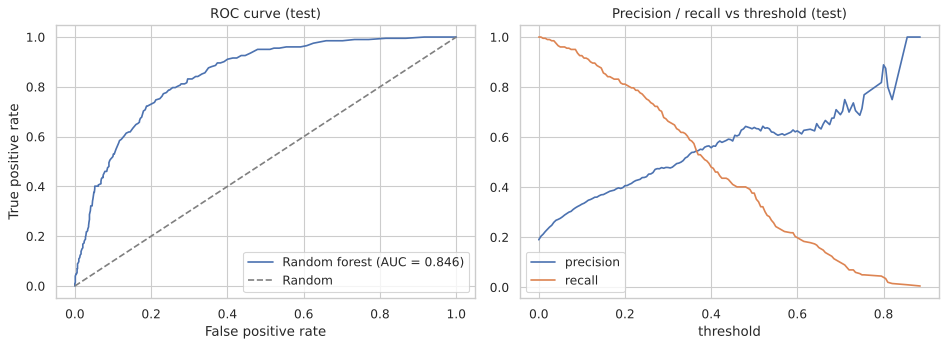

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

fpr, tpr, _ = roc_curve(y_test, y_pred)
axes[0].plot(fpr, tpr, label=f'Random forest (AUC = {test_auc:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Random')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curve (test)'); axes[0].legend()

prec, rec, thr = precision_recall_curve(y_test, y_pred)
axes[1].plot(thr, prec[:-1], label='precision')
axes[1].plot(thr, rec[:-1], label='recall')
axes[1].set_xlabel('threshold'); axes[1].set_title('Precision / recall vs threshold (test)')
axes[1].legend()
plt.tight_layout()
plt.show()

In [32]:
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_t = thr[np.argmax(f1)]
print(f'Threshold that maximises F1 on test: {best_t:.2f}  (shown for reference; the service uses 0.5 by default)')
print()
print('Classification report at threshold 0.5:')
print(classification_report(y_test, (y_pred >= 0.5).astype(int), target_names=['not good', 'good']))

Threshold that maximises F1 on test: 0.28  (shown for reference; the service uses 0.5 by default)

Classification report at threshold 0.5:
              precision    recall  f1-score   support

    not good       0.87      0.95      0.91       862
        good       0.64      0.38      0.47       202

    accuracy                           0.84      1064
   macro avg       0.75      0.66      0.69      1064
weighted avg       0.82      0.84      0.82      1064



At the default 0.5 threshold the model is **precise** — when it says *good*, it is usually right — but it misses a share of the good wines. If the goal is to send *every* promising batch to the tasting panel, a lower threshold (around 0.3) trades some precision for much better recall. The service returns the probability, so the user can choose the threshold.

### Feature importance of the final model

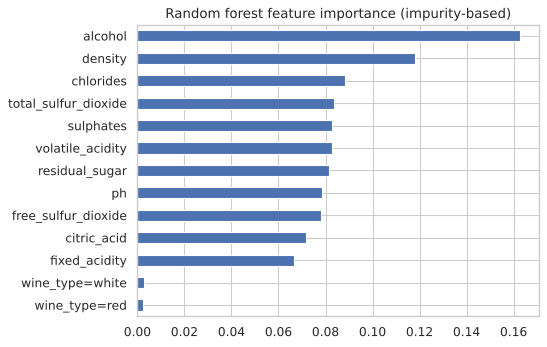

In [33]:
imp = pd.Series(final_model.feature_importances_, index=dv.get_feature_names_out()).sort_values()
imp.plot.barh(figsize=(7, 4.5), color='#4C72B0')
plt.title('Random forest feature importance (impurity-based)')
plt.tight_layout()
plt.show()

Alcohol is the most important feature, followed by density and chlorides — consistent with the correlation and mutual-information analysis in the EDA. `wine_type` is the least important feature: the chemistry already captures most of the red/white difference.

### Sanity check: a single prediction (same format the web service receives)

In [34]:
wine = df_test.iloc[0][features].to_dict()
print(wine)
X = dv.transform([wine])
print('P(good) =', round(final_model.predict_proba(X)[0, 1], 3), '| actual quality:', df_test.iloc[0].quality)

{'fixed_acidity': 6.4, 'volatile_acidity': 0.3, 'citric_acid': 0.16, 'residual_sugar': 7.5, 'chlorides': 0.05, 'free_sulfur_dioxide': 55.0, 'total_sulfur_dioxide': 191.0, 'density': 0.9959, 'ph': 3.17, 'sulphates': 0.49, 'alcohol': 9.0, 'wine_type': 'white'}
P(good) = 0.0 | actual quality: 5


## 7. Summary

* Cleaned the data: unified red + white, normalised column names, **removed 1,177 duplicate rows** to prevent leakage between train and test.
* EDA: alcohol is the dominant signal; density, volatile acidity and chlorides follow. `wine_type` adds little by itself.
* Compared four tuned model families; **Random Forest** won on 5-fold CV and reaches the test AUC shown above.
* The final training procedure lives in `train.py` (it saves `model.bin` with the `DictVectorizer` and the model), and `predict.py` serves it with Flask.